# Hand joint ranges: version 0 vs version 1

**What changed.** In version 0, every finger and thumb segment could bend
*backwards* (hyperextend) by up to 60°, as in
`monkey_arm/right_arm_fingers_v0.xml`. The learned policies used this
heavily: RND and the supervised policy held finger joints beyond −20° in
about 26% of finger-joint steps, and beyond −45° in about 10%. That is the
"double-jointed" look. Version 1 restricts **extension only**:

- knuckles (d0, MCP): −20° at most;
- middle and end joints (d1, d2): −5° at most;
- the thumb's MCP and IP (d1, d2): −10° at most.

Flexion limits are unchanged. The thumb base (CMC) keeps its large
natural range, which the scripted pinch uses.

Version 1 also **couples** each finger's end joint to its middle joint
(DIP target = ⅔ × PIP target), as the tendons do. That gives 19 actions
instead of 23. This applies only to this project's model
(`ue/sim/hand.py`); the shared arm file and the PPO environment are
unchanged.

**How to read the videos.** Each video shows **v0 (left)** and **v1
(right)** doing the same sweep through the v0 range, viewed along the
joint's axis so the bend is seen in profile. When v1 is clamped at its
limit, its label bar turns **red (LIMIT)**. Positive angles = flexion
(toward the palm); negative = bending back.

**Please check:** (1) the v1 ranges look anatomically reasonable; (2) the
coupled finger curl looks natural; (3) nothing that a monkey hand can do
is lost (see the scripted-grasp check at the end).

*Regenerate with `scripts/make_hand_notebook.py`.*

In [ ]:
import numpy as np
from IPython.display import HTML, display

from ue.analysis.hand_demo import (HandPoser, joint_video, sequence_video,
                                   to_html_video)

posers = {"v0": HandPoser("v0"), "v1": HandPoser("v1")}
names = posers["v0"].names
hand_joints = names[7:]

## Range table

Changed rows are highlighted.

In [ ]:
rows = []
for j in names:
    a, b = posers["v0"].range_deg(j), posers["v1"].range_deg(j)
    changed = not np.allclose(a, b)
    style = ' style="background:#fde2c8"' if changed else ""
    coupled = ("follows ⅔ × " + j.replace("d2", "d1")
               if j.endswith("d2_flexion") and not j.startswith("thumb")
               else "")
    rows.append(f"<tr{style}><td>{j}</td><td>[{a[0]:+.0f}, {a[1]:+.0f}]"
                f"</td><td>[{b[0]:+.0f}, {b[1]:+.0f}]</td>"
                f"<td>{coupled}</td></tr>")
display(HTML("<table><tr><th>joint</th><th>v0 range (deg)</th>"
             "<th>v1 range (deg)</th><th>v1 coupling</th></tr>"
             + "".join(rows) + "</table>"))

joint,v0 range (deg),v1 range (deg),v1 coupling
shoulder_abduction,"[-15, +120]","[-15, +120]",
shoulder_flexion,"[-120, +120]","[-120, +120]",
shoulder_rotation,"[-30, +30]","[-30, +30]",
elbow_flexion,"[+0, +120]","[+0, +120]",
radial_pronation,"[-90, +120]","[-90, +120]",
wrist_flexion,"[-30, +30]","[-30, +30]",
wrist_abduction,"[-30, +30]","[-30, +30]",
thumb_d0_abduction,"[-30, +90]","[-15, +90]",
thumb_d0_flexion,"[-30, +30]","[-30, +30]",
thumb_d1_flexion,"[-60, +60]","[-10, +60]",


## Per-joint sweeps

One video per hand joint, grouped by digit. The 7 arm joints (shoulder,
elbow, pronation, wrist) are unchanged and not shown. The coupled end
joints (d2 of the index to pinky) are posed directly here, so their range
is visible; in the v1 environment they follow d1 (next section).

### Thumb

In [ ]:
joints = [n for n in hand_joints
          if n.startswith("thumb")]
for j in joints:
    # Coupled d2 joints are shown on the uncoupled v1 hand (same ranges).
    v1 = (HandPoser("v1_ranges") if j.endswith("d2_flexion")
          else posers["v1"])
    a, b = posers["v0"].range_deg(j), v1.range_deg(j)
    display(HTML(f"<b>{j}</b>: v0 [{a[0]:+.0f}, {a[1]:+.0f}] deg, "
                 f"v1 [{b[0]:+.0f}, {b[1]:+.0f}] deg"))
    display(HTML(to_html_video(joint_video(j, {"v0": posers["v0"],
                                                "v1": v1}))))

### Index

In [ ]:
joints = [n for n in hand_joints
          if n.startswith("index")]
for j in joints:
    # Coupled d2 joints are shown on the uncoupled v1 hand (same ranges).
    v1 = (HandPoser("v1_ranges") if j.endswith("d2_flexion")
          else posers["v1"])
    a, b = posers["v0"].range_deg(j), v1.range_deg(j)
    display(HTML(f"<b>{j}</b>: v0 [{a[0]:+.0f}, {a[1]:+.0f}] deg, "
                 f"v1 [{b[0]:+.0f}, {b[1]:+.0f}] deg"))
    display(HTML(to_html_video(joint_video(j, {"v0": posers["v0"],
                                                "v1": v1}))))

### Middle

In [ ]:
joints = [n for n in hand_joints
          if n.startswith("middle")]
for j in joints:
    # Coupled d2 joints are shown on the uncoupled v1 hand (same ranges).
    v1 = (HandPoser("v1_ranges") if j.endswith("d2_flexion")
          else posers["v1"])
    a, b = posers["v0"].range_deg(j), v1.range_deg(j)
    display(HTML(f"<b>{j}</b>: v0 [{a[0]:+.0f}, {a[1]:+.0f}] deg, "
                 f"v1 [{b[0]:+.0f}, {b[1]:+.0f}] deg"))
    display(HTML(to_html_video(joint_video(j, {"v0": posers["v0"],
                                                "v1": v1}))))

### Ring

In [ ]:
joints = [n for n in hand_joints
          if n.startswith("ring")]
for j in joints:
    # Coupled d2 joints are shown on the uncoupled v1 hand (same ranges).
    v1 = (HandPoser("v1_ranges") if j.endswith("d2_flexion")
          else posers["v1"])
    a, b = posers["v0"].range_deg(j), v1.range_deg(j)
    display(HTML(f"<b>{j}</b>: v0 [{a[0]:+.0f}, {a[1]:+.0f}] deg, "
                 f"v1 [{b[0]:+.0f}, {b[1]:+.0f}] deg"))
    display(HTML(to_html_video(joint_video(j, {"v0": posers["v0"],
                                                "v1": v1}))))

### Pinky

In [ ]:
joints = [n for n in hand_joints
          if n.startswith("pinky")]
for j in joints:
    # Coupled d2 joints are shown on the uncoupled v1 hand (same ranges).
    v1 = (HandPoser("v1_ranges") if j.endswith("d2_flexion")
          else posers["v1"])
    a, b = posers["v0"].range_deg(j), v1.range_deg(j)
    display(HTML(f"<b>{j}</b>: v0 [{a[0]:+.0f}, {a[1]:+.0f}] deg, "
                 f"v1 [{b[0]:+.0f}, {b[1]:+.0f}] deg"))
    display(HTML(to_html_video(joint_video(j, {"v0": posers["v0"],
                                                "v1": v1}))))

## Coupling: the end joint follows the middle joint

Left: v1 ranges with independent joints (`v1_ranges`, 23 actions).
Right: v1 with coupling (19 actions). The *middle* joint (d1) of every
finger is swept; with coupling, the end joint (d2) curls along at ⅔ of
the middle joint's angle.

In [ ]:
pair = {"v1 independent": HandPoser("v1_ranges"),
        "v1 coupled": posers["v1"]}
curl = lambda a: {f"{f}_d1_flexion": a for f in
                  ("index", "middle", "ring", "pinky")}
frames = sequence_video([("straight", curl(0)), ("half", curl(30)),
                         ("full", curl(60)), ("straight", curl(0))],
                        pair, view_joint="index_d1_flexion")
display(HTML(to_html_video(frames)))

## Whole-hand extremes

Every hand joint is driven to its *lower* limit ("bent back" as far as
allowed), then to its upper limit (a fist), then back to neutral. v0 on
the left and v1 on the right, seen from the side and then from the palm.

In [ ]:
def extreme(p, which):
    return {j: p.range_deg(j)[which] for j in hand_joints}

lo0, hi0 = extreme(posers["v0"], 0), extreme(posers["v0"], 1)
keys = [("neutral", {}), ("bent back", lo0), ("neutral", {}), ("fist", hi0),
        ("neutral", {})]
for view, name in [("index_d0_flexion", "side"), (None, "palm")]:
    v = None if view else [0, -1, 0.3]
    display(HTML(f"<b>{name} view</b>"))
    display(HTML(to_html_video(sequence_video(keys, posers, view_joint=view,
                                              view=v))))

## Random hand postures

What exploration noise does to the hand: 6 postures with every hand joint
drawn uniformly from its range (the v1 coupled joints follow their
leaders). Top row v0, bottom row v1.

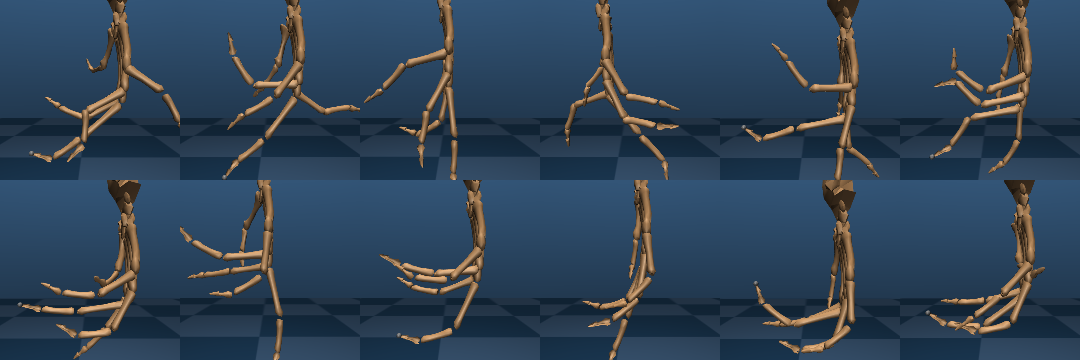

In [ ]:
from PIL import Image
rng = np.random.default_rng(0)
rows = []
for name, p in posers.items():
    tiles = []
    for k in range(6):
        u = rng.uniform(0, 1, len(hand_joints))
        pose = {j: p.range_deg(j)[0] + ui * (p.range_deg(j)[1]
                                              - p.range_deg(j)[0])
                for j, ui in zip(hand_joints, u)}
        p.pose(pose)
        p.look("index_d0_flexion")
        tiles.append(p.render()[::2, ::2])
    rows.append(np.concatenate(tiles, 1))
display(Image.fromarray(np.concatenate(rows, 0)))

## Does the hand still work? The scripted grasp

The scripted controller (`ue/teach/scripted.py`) is the demonstrator for
the version 1 training runs. It was re-run with the v1 hand. 40 trials
each:

| hand | free: lift | free: grasp | free: pinch | fixed: grasp |
|---|---|---|---|---|
| v0 | 57% | 62% | 82% | 68% |
| v1 | 57% | 60% | 82% | 68% |

A first version of the v1 ranges also limited the thumb base (CMC) to
−10° of extension. That dropped scripted lifting to 20%, because the pinch
uses the extended thumb as a post. The thumb base was restored to its
natural range.

Below: the scripted grasp with the v1 hand (physics, 4 free blocks).

In [ ]:
from ue.sim.env import PlayEnv
from ue.teach.scripted import ScriptedGrasp

env = PlayEnv(seed=3, p_fixed=0.0, hand="v1", render_size=(300, 400))
frames = []
for ep in range(4):
    obs, _ = env.reset()
    ctrl = ScriptedGrasp(env)
    for k in range(env.max_steps):
        obs, _, _, _, info = env.step(ctrl(obs))
        if k % 2 == 0:
            frames.append(env.render("close"))
display(HTML(to_html_video(frames)))

## Checklist

- [ ] v1 finger and thumb ranges look reasonable (per-joint videos)
- [ ] coupled curl looks natural
- [ ] "bent back" extremes are acceptable in v1
- [ ] the hand can still grasp and lift (scripted grasp)

If anything should change (e.g. allow more knuckle extension, a different
coupling ratio, no coupling), the values are in `ue/sim/hand.py`
(`_v1_ranges`, `DIP_RATIO`, `HANDS`).